<a href="https://colab.research.google.com/github/Jorge-UC3M/ML-P1/blob/main/C1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 1: Predicción de subscripción a un producto bancario
## **Alumnos:**
*   María Arias Rodríguez, 100522272
*   Jorge Ignacio Castañeda Vallenilla, 100522273

## **Link a github:** https://github.com/maria-env/bank-deposit-prediction-ml

## <u>**Parte 0: Preparación centralizada**</u>

In [ ]:
# 1. Librerías de manipulación de datos y utilidades
import pandas as pd
import numpy as np
import joblib
import time
import math

# 2. Librerías de visualización
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Scikit-Learn: Preprocesamiento y Selección de Modelos
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler

# 4. Scikit-Learn: Modelos (Todos los que hemos usado)
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier, HistGradientBoostingClassifier, RandomForestClassifier, StackingClassifier

# 5. Scikit-Learn: Métricas y Evaluación
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

## <u>**Parte 1: EDA**</u>

Antes de empezar a entrenar modelos con el fin de trabajar sobre los datos, vamos a revisar el dataset para conocer sus características, variables y otros detalles que afectarán al preprocesado, a la estructura del pipeline y al tipo de modelo que vamos a emplear para las predicciones. Hemos decidido que para nuestra práctica utilizaremos para el fichero de datos bank_09, ya que hemos decidido utilizar los dos últimos dígitos del primer NIA (72).

Primero de todo, insertamos las librerías, cargamos los datos y echamos un primer vistazo.

In [ ]:
# Primero cargamos el archivo que vamos a utilizar
df = pd.read_pickle('bank_09.pkl')

# Vistazo rápido de las primeras filas
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes


A continuación, vamos a comprobar de qué tipo son nuestros datos y cuántos nulos hay.

In [ ]:
# Vemos los tipos de datos y si hay alguno nulo
print(df.info())

# Hacemos conteo de los nulos
print("\nValores faltantes por columna: ")
print(df.isnull().sum())

<class 'pandas.DataFrame'>
Index: 11000 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        11000 non-null  int64 
 1   job        10903 non-null  object
 2   marital    10718 non-null  object
 3   education  11000 non-null  object
 4   default    11000 non-null  object
 5   balance    11000 non-null  int64 
 6   housing    11000 non-null  object
 7   loan       11000 non-null  object
 8   contact    11000 non-null  object
 9   day        11000 non-null  int64 
 10  month      11000 non-null  object
 11  duration   11000 non-null  int64 
 12  campaign   11000 non-null  int64 
 13  pdays      11000 non-null  int64 
 14  previous   11000 non-null  int64 
 15  poutcome   11000 non-null  object
 16  deposit    11000 non-null  object
dtypes: int64(7), object(10)
memory usage: 1.5+ MB
None

Valores faltantes por columna: 
age            0
job           97
marital      282
education      0
default  

Si ejecutamos el código anterior, podemos ver que el dataset contiene 11000 entradas y 17 columnas. Además, podemos ver que la mayoría de columnas no tienen datos nulos, solamente encontramos datos faltantes en la columna "job" con 97, y en la columna "marital" con 282. Aunque encontramos un caso especial que el programa pasa por alto, pdays cuenta con nulos disfrazados de "-1", que trataremos con feature engineering más adelante.

### <u>EDA Categórico</u>

Conocidos un poco mejor nuestros datos, decidimos explorar más en detalle algunas de las features. Comenzamos con los distintos valores de las variables categóricas así como su frecuencia de aparición en el dataset

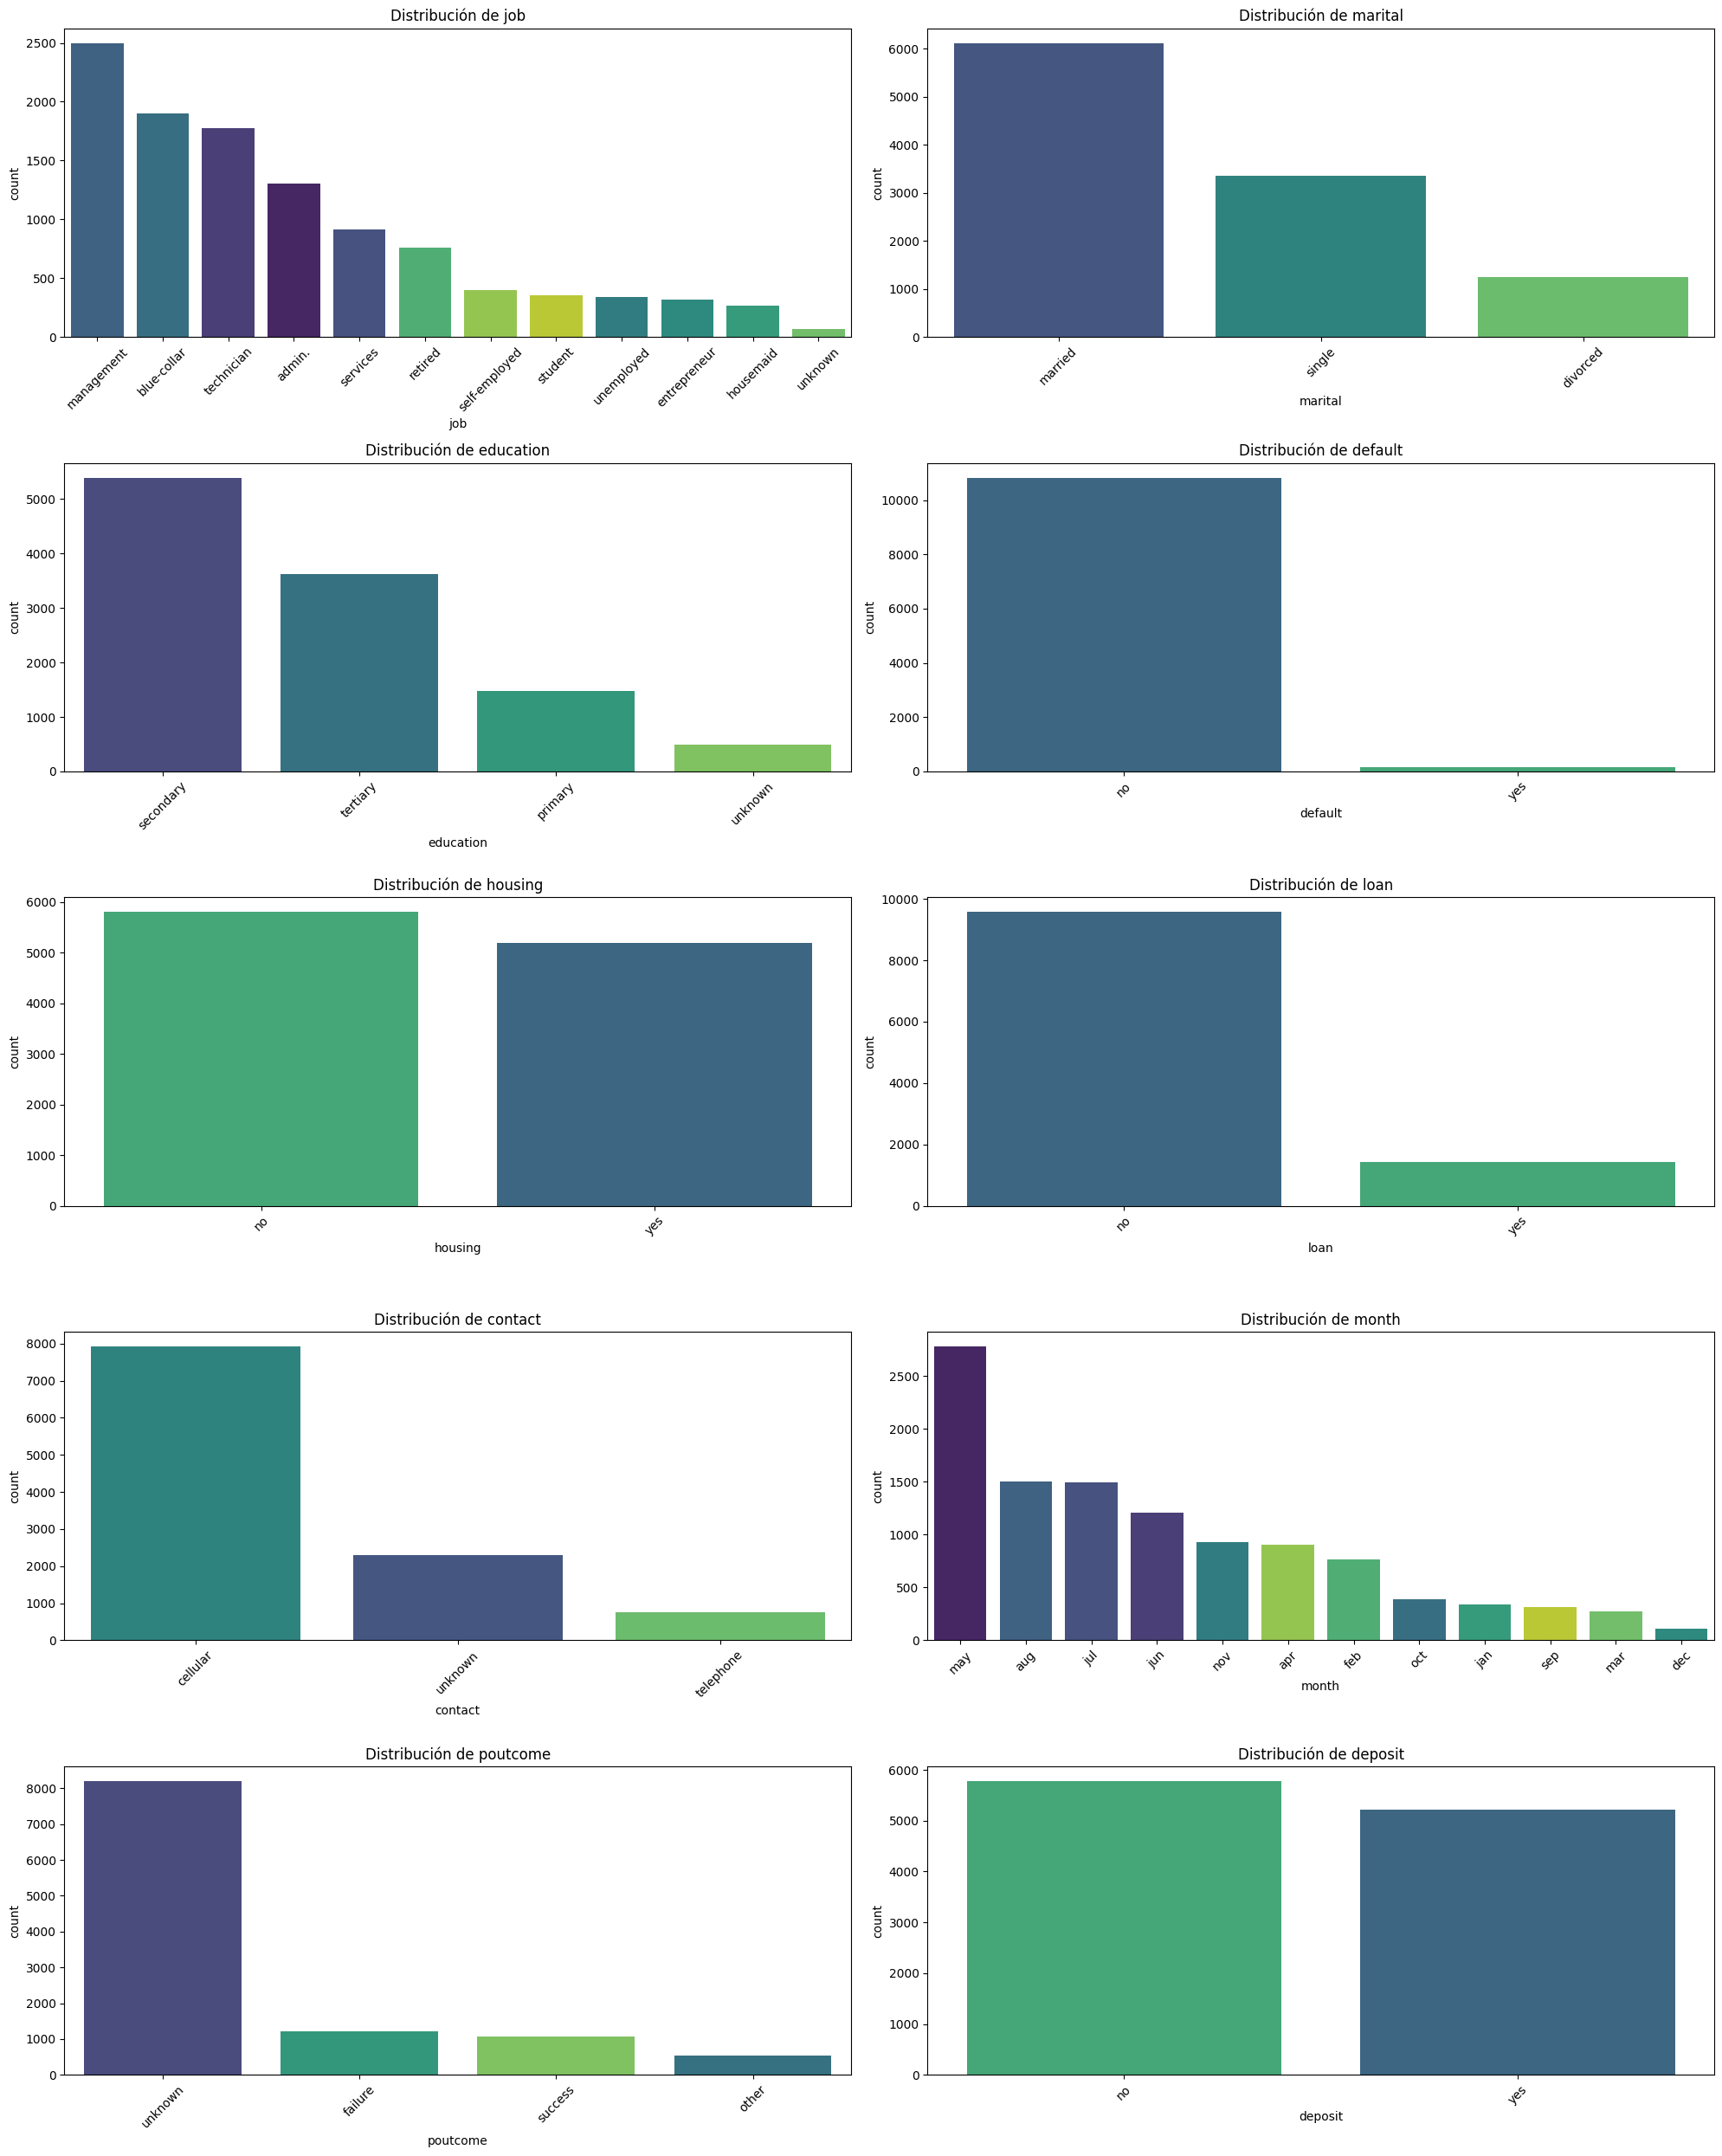

In [ ]:
cols = df.select_dtypes(include=['object']).columns
n_cols = 2
n_rows = math.ceil(len(cols) / n_cols)

plt.figure(figsize=(20, n_rows * 5))

for i, col in enumerate(cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.countplot(x=col, data=df, hue=col, palette='viridis', legend=False, order=df[col].value_counts().index)
    plt.title(f'Distribución de {col}')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Podemos observar el número aproximado de instancias que tiene cada una de las features categóricas y compararlas visualmente sin tener que meternos a leer porcentajes y datos engorrosos. Los datos han sido organizados por cantidad de apariciones para tener una mejor comparativa de cada feature.


### <u>EDA Numérico</u>

A continuación evaluaremos también las variables numéricas, comenzando con algunos cálculos estándar

In [ ]:
# Estadísticas de las columnas numéricas
print(df.describe())

                age       balance           day      duration     campaign  \
count  11000.000000  11000.000000  11000.000000  11000.000000  11000.00000   
mean      41.252727   1529.139273     15.660818    372.524909      2.50800   
std       11.940474   3217.396248      8.417970    347.515713      2.72221   
min       18.000000  -6847.000000      1.000000      2.000000      1.00000   
25%       32.000000    122.750000      8.000000    138.000000      1.00000   
50%       39.000000    549.500000     15.000000    255.000000      2.00000   
75%       49.000000   1711.000000     22.000000    498.000000      3.00000   
max       95.000000  81204.000000     31.000000   3881.000000     63.00000   

              pdays      previous  
count  11000.000000  11000.000000  
mean      51.308636      0.828000  
std      108.782842      2.282936  
min       -1.000000      0.000000  
25%       -1.000000      0.000000  
50%       -1.000000      0.000000  
75%       20.250000      1.000000  
max      

También mostramos los valores de las variables numéricas y la distribución de sus valores

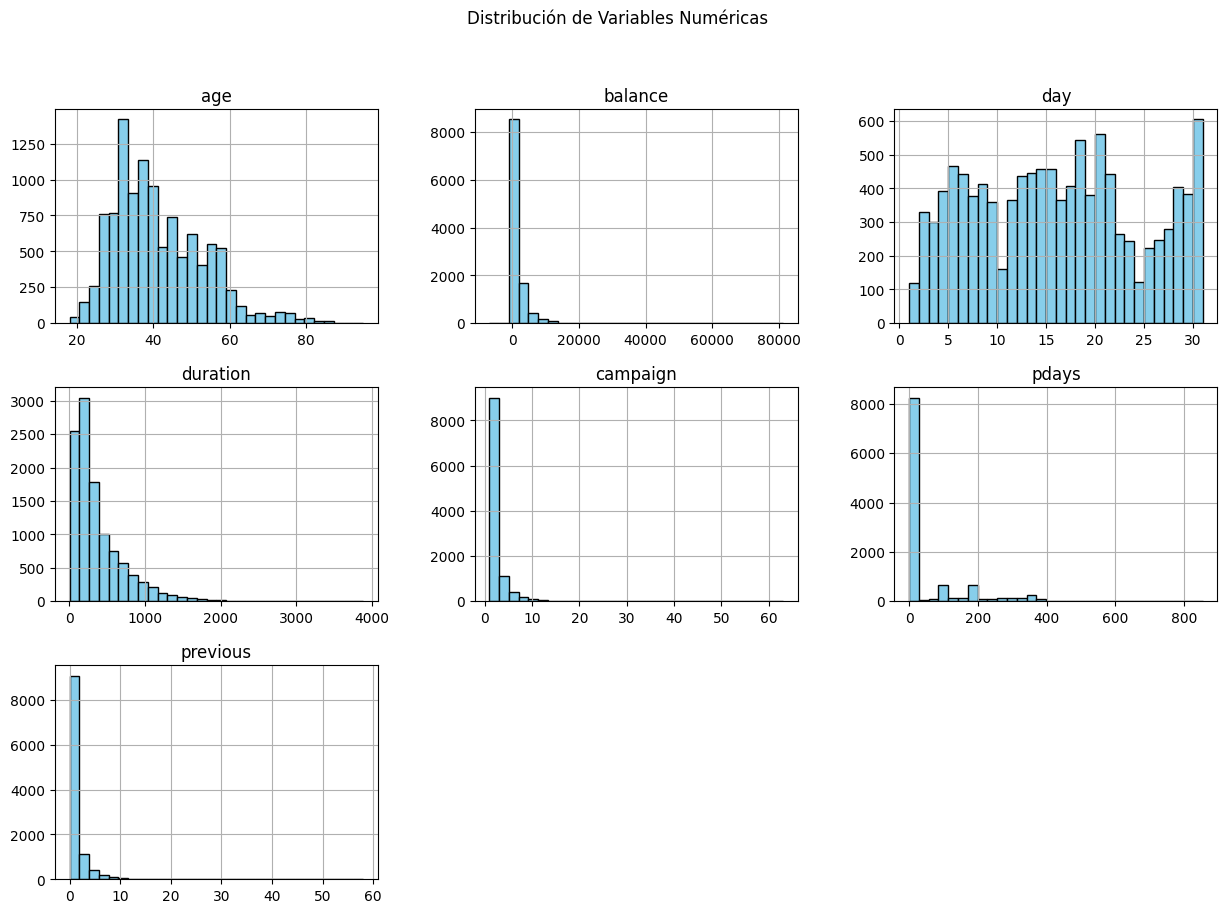

In [ ]:
# Histograma de todas las variables numéricas
df.hist(bins=30, figsize=(15, 10), color='skyblue', edgecolor='black')
plt.suptitle('Distribución de Variables Numéricas')
plt.show()

Podemos observar en las diferentes gráficas que la frecuencia de valores en las variables numérica son muy variados. Se identifican distribuciones muy constantes en sus rangos y casos mas extremos donde la mayoría de valores tienden a un punto específico.

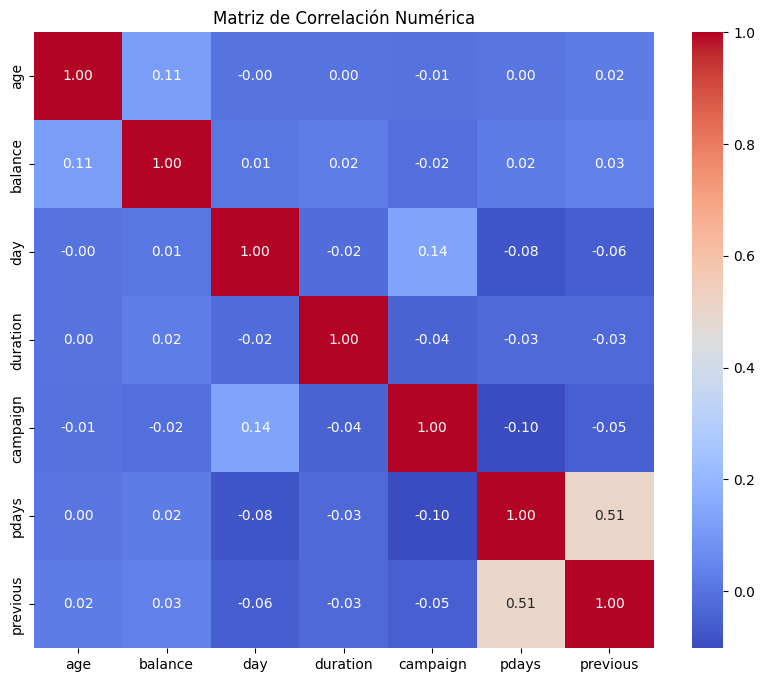

In [ ]:
# Calculamos la correlación

plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación Numérica')
plt.show()

Por otro lado, si analizamos las variables numéricas hay una descripción que destaca. La feature pdays menciona que para simular el valos "sin contacto" o "desconocido" utiliza el valor -1, que a diferencia del NULL puede dar confundir al modelo al tratarlo como a un valor normal.

In [ ]:
# Contamos cuántos -1 hay en la columna pdays
num_menos_uno = (df['pdays'] == -1).sum()
porcentaje_menos_uno = (df['pdays'] == -1).mean() * 100

print(f"Cantidad de valores -1 en pdays: {num_menos_uno}")
print(f"Porcentaje sobre el total: {porcentaje_menos_uno:.2f}%")

Cantidad de valores -1 en pdays: 8203
Porcentaje sobre el total: 74.57%


Como podemos observar en los resultados obtenidos podemos observar que los valores raros de pdays es de un 74,57%. Lo cual definitivamente tendremos que tratar consecuentemente para que el modelo que entrenemos generalice de manera correcta y sepa interpretar estos datos correctamente.

### <u>EDA del target</u>

Por último vamos a hacer un estudio del target (deposit).

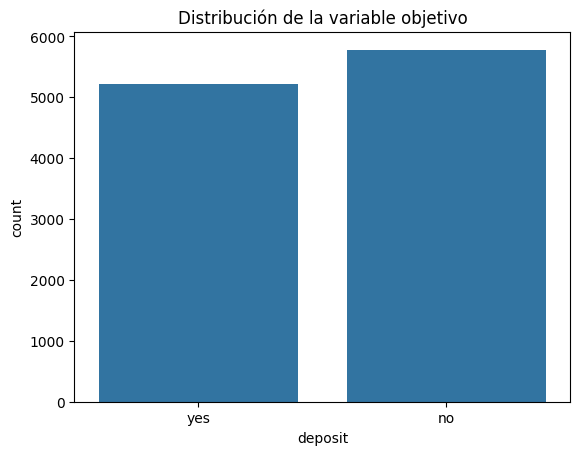

deposit
no     0.525455
yes    0.474545
Name: proportion, dtype: float64


In [ ]:
sns.countplot(x='deposit', data=df)
plt.title('Distribución de la variable objetivo')
plt.show()

print(df['deposit'].value_counts(normalize=True)) # Utilizamos normalize para ver porcentajes

Al analizar la variable deposit, podemos ver que un 52.54% de la muestra corresponde a clientes que no encontraron el depósito, mientras que un 47.46% de los clientes sí lo hicieron. Como la proporción es muy cercana al 50%, consideramos que el dataset está equilibrado, esto simplifica el entrenamiento ya que podremos utilizar el accuracy como métrica valida para comparar modelos.

### <u>Preproceso de pdays: Feature engineering</u>

Antes de continuar, vamos a hacer en este apartado el preproceso de pdays para evitar que sea más complicado una vez hecho el split. Para ello, vamos a crear una variable binaria para distinguir de los que han tenido algún tipo de contacto y los que no, y después sustituir todos los -1 de pdays por NaN.

In [ ]:
# Creamos contacted_before (binaria de 0 o 1)
df['contacted_before'] = (df['pdays'] != -1).astype(int)

# Reemplazamos los -1 por NaN
df['pdays'] = df['pdays'].replace(-1, np.nan)

print(f"contacted_before - distribución:\n{df['contacted_before'].value_counts()}\n")
print(f"pdays - valores nulos tras reemplazo: {df['pdays'].isna().sum()}")

contacted_before - distribución:
contacted_before
0    8203
1    2797
Name: count, dtype: int64

pdays - valores nulos tras reemplazo: 8203


## <u>**Parte 2: Decidir cómo se va a realizar la evaluación**</u>

Para estimar el rendimiento de nuestros modelos, dividiremos el dataset original en dos conjuntos independientes. Es por esto que utilizaremos el 66% para el entrenamiento y un 33% para el test. A su vez subdividiremos la parte de train en 3 usando KFold para evitar cualquier tipo de Data Leakage durante el entrenamiento del modelo o su afinamiento. Aplicando lo mencionado el código que realizará esta parte queda de la siguiente manera

In [ ]:
# Definimos variables independientes (X) y objetivo (y)
X = df.drop('deposit', axis=1)
y = df['deposit']

# División train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.33,
    random_state=100522273,
    stratify=y
)

# Nos hará falta tener un mapeo para alguna celda más adelante
y_train_num = y_train.map({'yes': 1, 'no': 0})
y_test_num = y_test.map({'yes': 1, 'no': 0})

print(f"Dataset de entrenamiento: {X_train.shape[0]} filas")
print(f"Dataset de test: {X_test.shape[0]} filas")

kf = KFold(n_splits=3, shuffle=True, random_state=100522273) # Aquí queda definido el tipo de fold que haremos a partir de ahora

Dataset de entrenamiento: 7370 filas
Dataset de test: 3630 filas


### <u>Preprocesado e inner</u>

Para la parte de preprocesado también hemos de considerar que nuestro dataset tiene variables categóricas y variables numéricas, las cuales no pueden ser tratadas de la misma manera. La mejor herramienta para hacer esta diferenciación es usar un ColumnTransformer, con los siguientes pipelines.

#### <u>Pipeline para variables numéricas:</u>
Imputación (mediana) -> Escalado (por decidir)

El pipeline de variables numéricas tendrá que pasar primero por la imputación, para completar los campos desconocidos de las features numéricas, esto se lo haremos con la mediana de los valores conocidos, puesto que es resistente a los valores atípicos de los extremos. Tras tener el dataset completo lo que haremos es escalar las variables para que todas tengan un peso proporcional, compensando la diferencia en los rangos de cada una.

#### <u>Pipeline para variables categóricas:</u>

Imputación (moda) -> One-hot encoding

El pipeline de variables categóricas realiza también una imputación por moda, puesto que no podemos ordenar de ninguna manera lógica los elementos de estas features, lo más lógico será escoger la clase mayoritaria entre las que tiene cada variable para completar campos vacíos. La segunda parte del pipeline será aplicar el one-hot encoding, que nos permite pasar texto a vectores binarios que le dicen al ordenador de forma que pueda entender que hay diferentes clases.

#### <u>Pipeline principal:</u>
Preprocesado (ColumnTransformer) -> Modelo (a elegir)

El pipeline principal se centra en unificar los pipelines del preprocesado y el modelo, terminando el diseño de todos los procesos por los que tienen que pasar las instancias del DataSet.

Para el scoring de los modelos que entrenemos usaremos el accuracy.

## <u>**Parte 3: Métodos básicos: KNN y trees**</u>

Antes de comenzar, tal y como mencionamos al final del apartado anterior, tenemos que aplicar una serie de reglas según el tipo de variable con el que estemos tratando, para ello, primero tendremos que identificar qué columnas contienen números y cuáles son texto.

In [ ]:
# Separamos las columnas por tipo de dato
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

print(f"Variables numéricas ({len(num_cols)}): {list(num_cols)}")
print(f"Variables categóricas ({len(cat_cols)}): {list(cat_cols)}")

Variables numéricas (8): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'contacted_before']
Variables categóricas (9): ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


Una vez separadas las columnas según el tipo de dato, podemos comenzar a hacer la parte del preprocesamiento de la siguiente forma:

In [ ]:
# Camino para números (mediana y escalado)
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())  # Lo usamos como punto de partida
])

# Camino para texto (moda y dummies)
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Unión de ambos caminos
preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

### <u>Método de escalado</u>

Para este paso, vamos a utilizar el algortimo KNN con sus parámetros por defecto (K=5). De esta forma, el escalador con mejor puntuación será el elegido.

In [ ]:
# Definimos los 3 escaladores a probar
escaladores = [
    ('StandardScaler', StandardScaler()),
    ('MinMaxScaler', MinMaxScaler()),
    ('RobustScaler', RobustScaler())
]

print("Resultados de la evaluación interna (3-fold CV):")
print("-" * 50)

for nombre, objeto_escalador in escaladores:

    # Redefinimos el transformer numérico con el escalador actual
    num_transformer_temp = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', objeto_escalador)
    ])

    # Montamos el preprocesador con ese transformer nuevo
    preprocessor_temp = ColumnTransformer(transformers=[
        ('num', num_transformer_temp, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

    # Creamos el pipeline final con KNN
    full_pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor_temp),
        ('knn', KNeighborsClassifier())
    ])

    # Evaluamos
    scores = cross_val_score(full_pipeline, X_train, y_train, cv=kf, scoring='accuracy')
    print(f"{nombre}: Accuracy = {scores.mean():.4f}")

Resultados de la evaluación interna (3-fold CV):
--------------------------------------------------
StandardScaler: Accuracy = 0.8026
MinMaxScaler: Accuracy = 0.7393
RobustScaler: Accuracy = 0.7725


Después de haber hecho la validación cruzada con KNN, podemos ver que el escalador que ofrece mejor rendimiento es el StandardScaler, con una Accuracy = 0.8047.

Podemos ver que hay una gran diferencia con respecto al MinMaxScaler (casi 8 puntos), lo que sugiere que la distribución de nuestras variables, como edad o balance, funciona mejor cuando se estandariza (media 0 y desviación típica 1) que cuando se acota a un rango fijo.

Por otro lado, podemos ver que la diferencia con el RobustScaler no es tan grande, lo que podría significar que nuestro dataset tiene algunos valores atípicos, pero no son lo suficientemente agresivos como para superar al StandardScaler.

In [ ]:
# Usamos StandardScaler como es el que hemos comprobado que da mejores resultados
num_transformer_final = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor_final = ColumnTransformer(transformers=[
    ('num', num_transformer_final, num_cols),
    ('cat', cat_transformer, cat_cols)
])

### <u>Métodos</u>

#### <u>Hiper Parámetros por omisión</u>

In [ ]:
# Dummy Classifier
dummy_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_final),
    ('dummy', DummyClassifier(strategy='most_frequent'))
])
dummy_scores = cross_val_score(dummy_pipeline, X_train, y_train, cv=kf, scoring='accuracy')
print(f"=== Baseline (DummyClassifier) ===")
print(f"Accuracy: {dummy_scores.mean():.4f} (+/- {dummy_scores.std():.4f})\n")

# KNN con hiperparámetros por omisión
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_final),
    ('knn', KNeighborsClassifier())
])
t_start = time.time()
knn_scores = cross_val_score(knn_pipeline, X_train, y_train, cv=kf, scoring='accuracy')
t_end = time.time()

print(f"=== KNeighbors (hiperparámetros por omisión) ===")
print(f"Tiempo:     {t_end - t_start:.5f} segundos")
print(f"Accuracy: {knn_scores.mean():.4f} (+/- {knn_scores.std():.4f})\n")

# DecisionTree con hiperparámetros por omisión
dtree_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_final),
    ('dtree', DecisionTreeClassifier(random_state=100522273))
])
t_start = time.time()
dtree_scores = cross_val_score(dtree_pipeline, X_train, y_train, cv=kf, scoring='accuracy')
t_end = time.time()

print(f"=== DecisionTree (hiperparámetros por omisión) ===")
print(f"Tiempo:     {t_end - t_start:.5f} segundos")
print(f"Accuracy: {dtree_scores.mean():.4f} (+/- {dtree_scores.std():.4f})\n")

# Tabla resumen
tabla_defaults_basicos = pd.DataFrame({
    'Modelo': ['Dummy (baseline)', 'KNN (default)', 'DecisionTree (default)'],
    'Accuracy (media)': [dummy_scores.mean(), knn_scores.mean(), dtree_scores.mean()],
    'Accuracy (std)':  [dummy_scores.std(),  knn_scores.std(),  dtree_scores.std()]
})
print(tabla_defaults_basicos.to_string(index=False))

=== Baseline (DummyClassifier) ===
Accuracy: 0.5255 (+/- 0.0030)

=== KNeighbors (hiperparámetros por omisión) ===
Tiempo:     0.17488 segundos
Accuracy: 0.8026 (+/- 0.0023)

=== DecisionTree (hiperparámetros por omisión) ===
Tiempo:     0.20953 segundos
Accuracy: 0.7834 (+/- 0.0073)

                Modelo  Accuracy (media)  Accuracy (std)
      Dummy (baseline)          0.525509        0.002959
         KNN (default)          0.802578        0.002327
DecisionTree (default)          0.783447        0.007274


#### <u>Árboles poco profundos</u>

=== DecisionTree poco profundo ===
Tiempo:     0.16242 segundos
Accuracy: 0.7682 (+/- 0.0102)



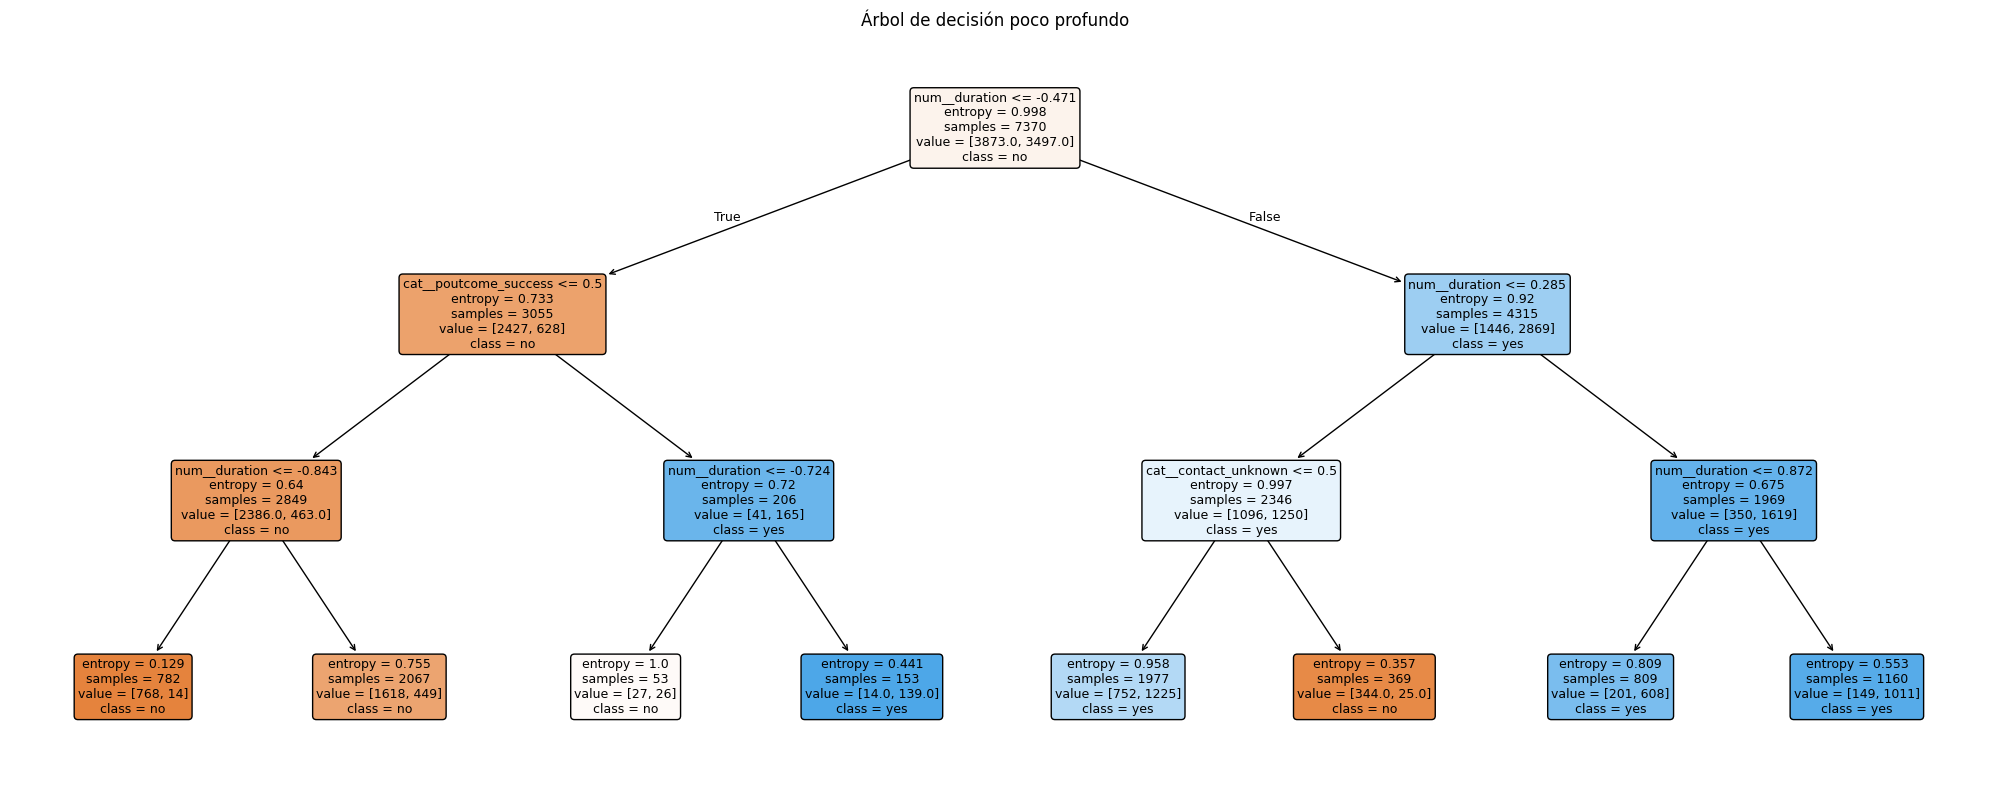

In [ ]:
# Definimos la Pipeline
dtree_shallow = Pipeline(steps=[
    ('preprocessor', preprocessor_final),
    ('dtree', DecisionTreeClassifier(max_depth=3, criterion='entropy', random_state=100522273))
])

# Contamos el tiempo que tarda en entrenar con CV
t_start = time.time()
shallow_scores = cross_val_score(dtree_shallow, X_train, y_train, cv=kf, scoring='accuracy')
t_end = time.time()

print(f"=== DecisionTree poco profundo ===")
print(f"Tiempo:     {t_end - t_start:.5f} segundos")
print(f"Accuracy: {shallow_scores.mean():.4f} (+/- {shallow_scores.std():.4f})\n")

# Entrenamos sobre X_train completo solo para visualizar el árbol
dtree_shallow.fit(X_train, y_train)

feature_names = preprocessor_final.get_feature_names_out()
class_names = dtree_shallow.named_steps['dtree'].classes_

# Mostramos un gráfico de los datos del árbol
plt.figure(figsize=(20, 8))
plot_tree(
    dtree_shallow.named_steps['dtree'],
    feature_names=feature_names,
    class_names=[str(c) for c in class_names],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Árbol de decisión poco profundo")
plt.tight_layout()
plt.show()

#### <u>Optimización de HiperParémetros de los métodos</u>

A continuación empezamos a introducir la HPO para los modelos KNN y Decision Tree (ambos de tipo Classifier) que nos permita obtener incluso mejores resultados al probar varias combinaciones de hiperparámetros.

In [ ]:
# Definimos la Pipeline
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_final),
    ('knn', KNeighborsClassifier())
])

# Rejilla de parámetros para KNN
knn_param_grid = {
    'knn__n_neighbors': [13, 14, 15, 16, 17],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2] # 1: Manhattan, 2: Euclidean
}

# Ejecución del GridSearchCV
t_start = time.time()
grid_knn = GridSearchCV(knn_pipeline, knn_param_grid, cv=kf, scoring='accuracy')
grid_knn.fit(X_train, y_train_num) #AQUI USAMOS EL y_train_num
t_end = time.time()
knn_time = t_end - t_start

# Resultados
print(f"=== KNN con HPO ===")
print(f"Tiempo HPO:    {knn_time:.5f} segundos")
print(f"Mejores params: {grid_knn.best_params_}")
print(f"Mejor score: {grid_knn.best_score_:.4f}")

=== KNN con HPO ===
Tiempo HPO:    6.28547 segundos
Mejores params: {'knn__n_neighbors': 16, 'knn__p': 2, 'knn__weights': 'distance'}
Mejor score: 0.8104


Nótese que hemos ejecutado el código varias veces para ir ajustando "manualmente" parámetros hasta encontrar el óptimo del problema

In [ ]:
dtree_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_final),
    ('dtree', DecisionTreeClassifier(random_state=100522273))
])

# Definición de la rejilla de parámetros
dtree_param_grid = {
    'dtree__criterion': ['gini', 'entropy'],
    'dtree__splitter': ['best', 'random'],
    'dtree__max_depth': [10, 15, 20, 25],
    'dtree__min_samples_split': [30, 50, 70, 100]
}

# Ejecución del GridSearchCV
t_start = time.time()
grid_dtree = GridSearchCV(dtree_pipeline, dtree_param_grid, cv=kf, scoring='accuracy')
grid_dtree.fit(X_train, y_train)
t_end = time.time()
tree_time = t_end - t_start

# Resultados
print(f"=== DecisionTree con HPO ===")
print(f"Tiempo HPO:     {tree_time:.5f} segundos")
print(f"Mejores params: {grid_dtree.best_params_}")
print(f"Mejor score: {grid_dtree.best_score_:.4f}")

=== DecisionTree con HPO ===
Tiempo HPO:     9.23175 segundos
Mejores params: {'dtree__criterion': 'gini', 'dtree__max_depth': 15, 'dtree__min_samples_split': 50, 'dtree__splitter': 'random'}
Mejor score: 0.8421


#### <u>Plots y razonamiento de los hiperparámetros</u>

Primero vamos a hacer unas gráficas para ver los efectos de los hiperparámetros en KNN.

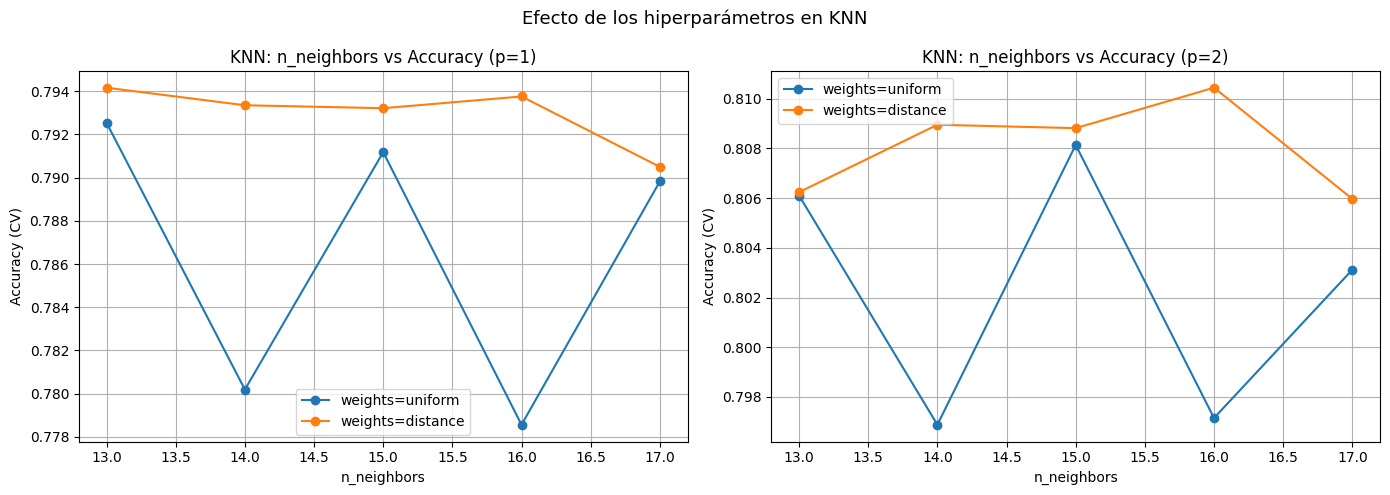

In [ ]:
cv_results = pd.DataFrame(grid_knn.cv_results_)

# Plot: n_neighbors vs accuracy para cada combinación de weights y p
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, [1, 2]):
    for weight in ['uniform', 'distance']:
        mask = (cv_results['param_knn__weights'] == weight) & (cv_results['param_knn__p'] == metric)
        subset = cv_results[mask].sort_values('param_knn__n_neighbors')
        ax.plot(
            subset['param_knn__n_neighbors'],
            subset['mean_test_score'],
            marker='o',
            label=f'weights={weight}'
        )
    ax.set_title(f'KNN: n_neighbors vs Accuracy (p={metric})')
    ax.set_xlabel('n_neighbors')
    ax.set_ylabel('Accuracy (CV)')
    ax.legend()
    ax.grid(True)

plt.suptitle('Efecto de los hiperparámetros en KNN', fontsize=13)
plt.tight_layout()
plt.show()

Conclusiones:

*   Impacto de weights: Se observa una clara superioridad del parámetro weights='distance' sobre weights='uniform'. Mientras que el peso uniforme presenta mucha inestabilidad, el peso por distancia suaviza la curva y mantiene un accuracy más alto y constante.
*   Influencia de p: Comparando ambas gráficas, la distancia euclídea (p=2) alcanza picos de precisión superiores (0.810 o más) frente a la distancia manhattan (p=1), que se queda en torno a 0.794.
*   Evolución de n_neighbors: Con pesos por distancia, el modelo es robusto al número de vecinos, alcanzando su rendimiento óptimo en k=16 para p=2, tal y como vimos en el apartado anterior.

Ahora vamos a hacer las gráficas para árboles.

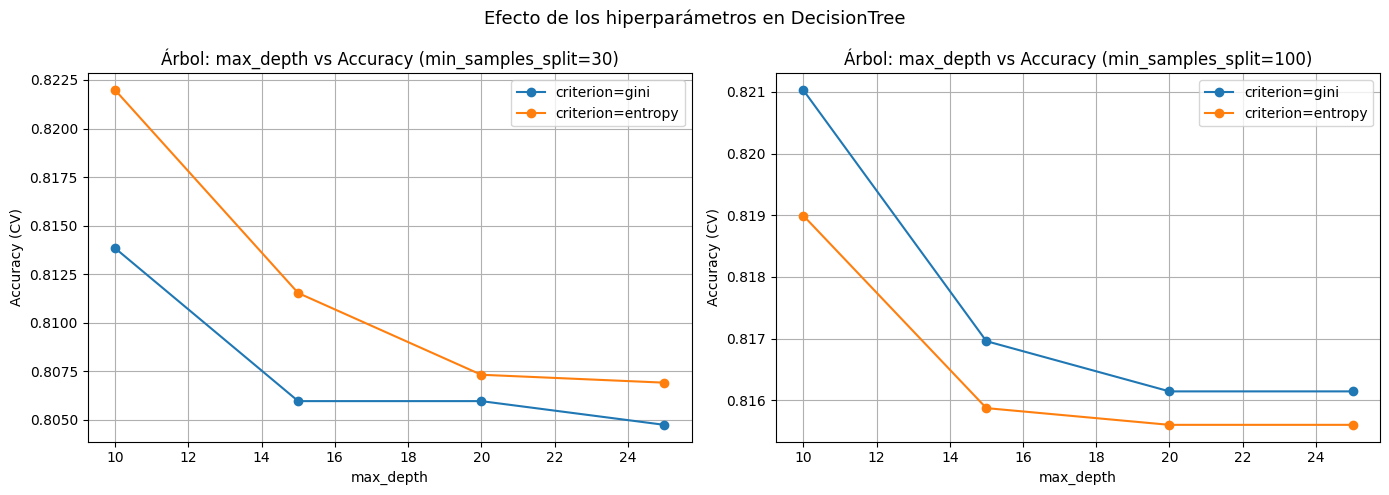

In [ ]:
cv_results_tree = pd.DataFrame(grid_dtree.cv_results_)

# Plot: max_depth vs accuracy para cada criterion
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, split_val in zip(axes, [30, 100]):
    for criterion in ['gini', 'entropy']:
        mask = (
            (cv_results_tree['param_dtree__criterion'] == criterion) &
            (cv_results_tree['param_dtree__min_samples_split'] == split_val) &
            (cv_results_tree['param_dtree__splitter'] == 'best')
        )
        subset = cv_results_tree[mask].sort_values('param_dtree__max_depth')
        ax.plot(
            subset['param_dtree__max_depth'],
            subset['mean_test_score'],
            marker='o',
            label=f'criterion={criterion}'
        )
    ax.set_title(f'Árbol: max_depth vs Accuracy (min_samples_split={split_val})')
    ax.set_xlabel('max_depth')
    ax.set_ylabel('Accuracy (CV)')
    ax.legend()
    ax.grid(True)

plt.suptitle('Efecto de los hiperparámetros en DecisionTree', fontsize=13)
plt.tight_layout()
plt.show()

Conclusiones:

*   Impacto de max_depth: Se observa una tendencia clara y descendente. El mejor rendimiento se obtiene con la profundidad más baja probada (max_depth=10). A medida que el árbol se hace más profundo, el accuracy cae, lo que indica que profundidades altas provocan overfitting al memorizar demasiado los datos de entrenamiento.
*   Criterio de división: En este caso, tenemos dos partes muy diferenciadas. Para un min_samples_split pequeño (30), podemos ver que entropy es mejor que Gini, sin embargo, si aumentamos el valor más, podemos ver que Gini se vuelve superior. En nuestro caso, usando GridSearch, el mejor parámetro de min_samples_split fue de 50 y tuvo mejor resultado Gini.
*   Mínimo de muestras para dividir: Con un valor de 30, el modelo alcanza su pico máximo de accuracy (más o menos 0.8225). Por otro lado, con un valor de 100, el modelo es más restrictivo y el accuracy máximo baja ligeramente (más o menos 0.821). Esto sugiere que permitir divisiones con menos muestras ayuda a capturar patrones más específicos sin llegar al ruido.

Aunque en las tendencias generales se observa que una profundidad de 10 es muy efectiva, GridSearch determinó que la mejor combinación global utiliza max_depth = 15 junto con un splitter random. Esto sugiere que introducir cierta aleatoriedad en las divisiones permite al árbol profundizar un poco más sin caer en overfitting, siempre que se mantenga un min_samples_split elevado (50) para asegurar que las hojas finales representen patrones significativos y no ruido.

## <u>**Parte 4: Métodos avanzados: Modelos lineales y SVMs**</u>

### <u>Evaluar con hiperparámetros por omisión</u>

Primero de todo, antes de realizar cualquier ajuste en los hiperparámetros, vamos a lanzar los modelos con los hiperparámetros por defecto.

In [ ]:
# Diccionario de modelos
modelos_omision = {
    'Lineal_Sin_L1': LogisticRegression(max_iter=1000, random_state=100522273),
    'Lineal_Con_L1': LogisticRegression(penalty='l1', solver='liblinear',
                                         max_iter=1000, random_state=100522273),
    'SVM_Base': SVC(random_state=100522273)
}

print(f"{'Modelo':25} | {'Accuracy':10} | {'Tiempo':10}")
print("-" * 50)

for nombre, modelo in modelos_omision.items():
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor_final),
        ('model', modelo)
    ])

    t_start = time.time()
    scores = cross_val_score(pipe, X_train, y_train, cv=kf, scoring='accuracy')
    t_end = time.time()

    mean_score = scores.mean()
    duration = t_end - t_start

    print(f"{nombre:25} | Accuracy: {mean_score:.4f} | Tiempo: {duration:.4f}s")

Modelo                    | Accuracy   | Tiempo    
--------------------------------------------------
Lineal_Sin_L1             | Accuracy: 0.8324 | Tiempo: 0.1865s
Lineal_Con_L1             | Accuracy: 0.8323 | Tiempo: 0.2523s
SVM_Base                  | Accuracy: 0.8516 | Tiempo: 1.9948s


Después de ejecutar el código, podemos ver que el modelo SVM supera a los modelos lineales, esto sugiere que la separación entre los clientes que contratan el depósito y los que no, probablemente no sea puramente lineal, y el kernel es capaz de capturar relaciones más complejas.

Por otro lado, la diferencia entre el método lineal con regularización y el que no la tiene es muy pequeña, lo que indica que, con los parámetros por defecto, el filtrado de variables con L1 no ha supuesto una ventaja competitiva inmediata, aunque ha simplificado el modelo.

Sin embargo, pese a que el modelo SVM supera a los lineales, hay que tener en cuenta que el tiempo de ejecución fue bastante mayor (los lineales no tardaron más de un segundo mientras que este tardó 2 segundos), por lo que tendremos que valorar si realmente compensa un mayor accuracy a cambio del incremento en el tiempo que tarda.

### <u>Ajuste de hiperparámtros</u>

In [ ]:
# Optimización de los modelos lineales
param_grid_lineal = {
    'model__penalty': ['l1', 'l2'],
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__solver': ['liblinear']
}

grid_lineal = GridSearchCV(
    Pipeline(steps=[('preprocessor', preprocessor_final), ('model',
                    LogisticRegression(max_iter=1000, random_state=100522273))]),
    param_grid_lineal, cv=kf, scoring='accuracy'
)

start = time.time()
grid_lineal.fit(X_train, y_train)
lineal_time = time.time() - start
print(f"Mejor Lineal: {grid_lineal.best_score_:.4f} con {grid_lineal.best_params_}")
print(f"Tiempo de entrenamiento (Lineal): {lineal_time:.4f} segundos")

# Optimización de SVM
param_grid_svm = {
    'model__C': [0.1, 1, 10],
    'model__kernel': ['linear', 'rbf']
}

grid_svm = GridSearchCV(
    Pipeline(steps=[('preprocessor', preprocessor_final), ('model', SVC(random_state=100522273))]),
    param_grid_svm, cv=kf, scoring='accuracy'
)

start = time.time()
grid_svm.fit(X_train, y_train)
svm_time = time.time() - start
print(f"Mejor SVM: {grid_svm.best_score_:.4f} con {grid_svm.best_params_}")
print(f"Tiempo de entrenamiento (SVM): {svm_time:.4f} segundos")

Mejor Lineal: 0.8323 con {'model__C': 100, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
Tiempo de entrenamiento (Lineal): 2.9514 segundos
Mejor SVM: 0.8516 con {'model__C': 1, 'model__kernel': 'rbf'}
Tiempo de entrenamiento (SVM): 16.3739 segundos


Como podemos ver, hemos sacado dos conclusiones al hacer el ajuste de hiperparámetros:

1.   Modelo Lineal: El mejor rendimiento se logra con regularización L1 y C = 100. Esto significa que el dataset se beneficia de una simplificación de atributos, eliminando aquellos que no aportan información relevante, además, prioriza clasificar bien los datos de entrenamiento, aunque la frontera de decisión sea más compleja. Con esto, podemos ver que su precisión final es de 83.23%. Además, podemos ver que ha tardado bastante poco (casi 3 segundos).
2.   SVM: Al igual que antes, sigue siendo el modelo ganador con un 85.16% de acierto, utilizando un kernel RBF y C = 1. El hecho de que el kernel RBF supere al lineal demuestra que la frontera de decisión entre los clientes que contratan y los que no, es compleja y no lineal. Además, al contrario que el modelo lineal, podemos ver que ha tardado algo más (16 segundos).


### <u>Atributos más relevantes</u>

A continuación, vamos a ver cuáles son los atributos más relevantes. En este caso, aunque hemos visto que SVM ofrece una mayor precisión, utilizamos la regresión logística para la extracción de la relevancia de atributos debido a que es más fácil de interpretar, ya que los coeficientes del modelo lineal nos permiten ver de forma más directa el impacto de cada variable sobre la decisión del cliente.

In [ ]:
nombres_features = preprocessor_final.get_feature_names_out()
coeficientes = grid_lineal.best_estimator_.named_steps['model'].coef_[0]

importancia = pd.DataFrame({
    'Atributo': nombres_features,
    'Importancia': coeficientes,
    'Abs_Importancia': np.abs(coeficientes)
}).sort_values(by='Abs_Importancia', ascending=False)

print("Atributos más relevantes")
print(importancia[['Atributo', 'Importancia']].head(10))

Atributos más relevantes
                 Atributo  Importancia
20          cat__job_None     9.695633
24      cat__marital_None     9.567333
45         cat__month_mar     2.451576
40         cat__month_dec     2.039222
3           num__duration     1.885849
48         cat__month_oct     1.782815
49         cat__month_sep     1.445023
37   cat__contact_unknown    -1.326061
52  cat__poutcome_success     1.275643
51    cat__poutcome_other    -0.903780


Gracias a los coeficientes del modelo lineal, podemos identificar qué factores empujan al cliente a contratar el depósito.

En primer lugar, podermos ver que los coeficientes más altos aparecen en las categorías marital_None y job_None. Esto revela que los clientes con datos sobre su estado civil y trabajo desconocidos tienden a contratar el depósito.

Por otra parte, se observa un impacto postivo en meses específicos como marzo, octubre y diciembre, mientras que en otros como enero y julio penalizan la probabilidad de éxito.

Por otro lado,  la duración de la llamada (num__duration) y el éxito de las campañas anteriores (cat__poutcome_success) dan a entender que clientes que pasan más tiempo en las llamadas y los que ya aceptaron el depósito en otras campañas tienen más probabilidades de aceptarlo.

Finalmente, podemos asumir que el valor negativo de cat__contact_unknown sugiere que no tener un método de contacto identificado reduce bastante las posibilidades de aceptar contratar el depósito.


## <u>**Parte 5: Tarea de elección abierta -- Ensamblado de modelos**</u>

Como tarea de elección abierta hemos seleccionado el ensamblado de modelos porque nos parece interesante el concepto. La combinación de varios modelos parece a primera vista una manera intrigante de obtener las predicciones para cualquier problema puesto que nos permite aprovechar de manera efectiva las características más ventajosas de cada uno de los modelos si se realiza de manera adecuada. Estamos emocionados por ver los resultados de los diferentes modelos ensamblados

### <u>Gradient Boosting</u>

In [ ]:
# Definimos el Pipeline
boosting_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_final),
    ('boosting', HistGradientBoostingClassifier(random_state=100522273))
])

# Preparamos los parámetros para el GridSearchCV
boosting_param_grid = {
    'boosting__learning_rate': [0.05, 0.1, 0.2],
    'boosting__max_iter': [100, 200],
    'boosting__max_depth': [3, 5, 10],
    'boosting__l2_regularization': [0.0, 0.1]
}

# Ejecución del GridSearchCV (Inner Loop)
t_start = time.time()
grid_boosting = GridSearchCV(boosting_pipeline, boosting_param_grid, cv=kf, scoring='accuracy')
grid_boosting.fit(X_train, y_train)
boosting_time = time.time() - t_start

# Resultados
print(f"=== Gradient Boosting con HPO ===")
print(f"Tiempo HPO:     {boosting_time:.5f} segundos")
print(f"Mejores params: {grid_boosting.best_params_}")
print(f"Mejor score:    {grid_boosting.best_score_:.4f}")

=== Gradient Boosting con HPO ===
Tiempo HPO:     21.57302 segundos
Mejores params: {'boosting__l2_regularization': 0.1, 'boosting__learning_rate': 0.2, 'boosting__max_depth': 5, 'boosting__max_iter': 100}
Mejor score:    0.8645


Este es el modelo en el que más esperanzas tenemos, nos parece que un modelo capaz de aprender de sus errores previos para ir mejorando iterativamente es una estrategia fantástica que nos permite obtener un resultado mucho mayor.

### <u>Random Forest</u>

In [ ]:
# Definimos el Pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor_final),
    ('rf', RandomForestClassifier(random_state=100522273))
])

# Rejilla de parámetros para optimizarlo
rf_param_grid = {
    'rf__n_estimators': [100, 200],
    'rf__max_depth': [10, 15, 20],
    'rf__min_samples_split': [5, 10],
    'rf__criterion': ['gini', 'entropy']
}

# Ejecución del GridSearchCV (Inner Loop)
t_start = time.time()
grid_rf = GridSearchCV(rf_pipeline, rf_param_grid, cv=kf, scoring='accuracy')
grid_rf.fit(X_train, y_train)
rf_time = time.time() - t_start

# Resultados
print(f"=== Random Forest con HPO ===")
print(f"Tiempo HPO:     {rf_time:.5f} segundos")
print(f"Mejores params: {grid_rf.best_params_}")
print(f"Mejor score:    {grid_rf.best_score_:.4f}")

=== Random Forest con HPO ===
Tiempo HPO:     41.42510 segundos
Mejores params: {'rf__criterion': 'gini', 'rf__max_depth': 20, 'rf__min_samples_split': 10, 'rf__n_estimators': 100}
Mejor score:    0.8563


El Random Forest lo hemos escogido al parecernos una opción súper curiosa, sobre todo debido a que cada árbol se entrena con subconjuntos diferentes de datos. También nos llama la atención que los diferentes árboles ni siquiera evalúan las mismas features, por lo que queremos ver cómo se mueve este árbol en comparación con el resto de modelos.

### <u>Voting Classifier</u>

In [ ]:
from sklearn.ensemble import VotingClassifier

# Recuperamos la alineación completa de campeones (los 6 modelos HPO)
estimadores_completos = [
    ('knn', grid_knn.best_estimator_),
    ('dtree', grid_dtree.best_estimator_),
    ('lineal', grid_lineal.best_estimator_),
    ('svm', grid_svm.best_estimator_),
    ('rf', grid_rf.best_estimator_),
    ('boosting', grid_boosting.best_estimator_)
]

# Creamos el Voting Classifier con todos los modelos
ensamblado_voting = VotingClassifier(
    estimators=estimadores_completos,
    voting='hard'
)

# Evaluamos
t_start = time.time()
voting_scores = cross_val_score(ensamblado_voting, X_train, y_train, cv=kf, scoring='accuracy')
voting_time = time.time() - t_start

print(f"=== Ensamblado: Voting Classifier (6 Modelos) ===")
print(f"Tiempo de validación: {voting_time:.4f} segundos")
print(f"Accuracy (CV):        {voting_scores.mean():.4f}")

=== Ensamblado: Voting Classifier (6 Modelos) ===
Tiempo de validación: 4.7334 segundos
Accuracy (CV):        0.8556


El Voting Classifier es una asamblea de modelos, que seguro funcionará estupendamente aunque pensamos que podría haber un poco de lastre de parte de los modelos con menor accuracy respecto de los mejores.

### <u>Stacking</u>

In [ ]:
# Incluimos todos los modelos entrenados hasta ahora
estimadores_base = [
    ('knn', grid_knn.best_estimator_),
    ('dtree', grid_dtree.best_estimator_),
    ('lineal', grid_lineal.best_estimator_),
    ('svm', grid_svm.best_estimator_),
    ('rf', grid_rf.best_estimator_),
    ('boosting', grid_boosting.best_estimator_)
]

stacking_clf = StackingClassifier(
    estimators=estimadores_base,
    final_estimator=LogisticRegression(random_state=100522273),
    cv=3
)

# Evaluamos
t_start = time.time()
stacking_scores = cross_val_score(stacking_clf, X_train, y_train, cv=kf, scoring='accuracy')
stacking_time = time.time() - t_start

Para el stacking hemos decidido coger los mejores modelos de cada categoría para realizar las predicciones a través del meta-modelo StackingClassifier. Pensamos que debería ser el mejor modelo de todos puesto que la "votación" está supervisada por el modelo superior que aprende dónde brilla cada uno de los modelos que le hemos incorporado.

Tras haber observado los modelos ensamblados hemos observado aquello que sospechábamos en cada uno de los modelos. Unir diferentes modelos de maneras que potencien sus características ha resultado ser un éxito y una subida en el accuracy bastante bueno. También la posibilidad de usar varios modelos ensamblados juntos (usar los otros modelos de ensamblado en el Voting y Stacking Classifiers).

Una vez añadidos estos modelos a los candidatos para ser el modelo final, tenemos la certeza de que será uno de los que ha aparecido en este apartado.

## <u>**Parte 6: Resultados y modelo final**</u>

### <u>Selección de modelo</u>

Para elegir la mejor alternativa primero vamos a proyectar un resumen de los resultados obtenidos en los apartados 3 y 4:

In [ ]:
# Miramos todos los modelos y los comparamos
tabla_resumen_final = pd.DataFrame({
    'Modelo': [
        'KNN (HPO)',
        'DecisionTree (HPO)',
        'Lineal L1 (HPO)',
        'SVM RBF (HPO)',
        'Random Forest (HPO)',
        'Voting (Hard)',
        'Gradient Boosting (HPO)',
        'Stacking Classifier'
    ],
    'Accuracy (CV)': [
        grid_knn.best_score_,
        grid_dtree.best_score_,
        grid_lineal.best_score_,
        grid_svm.best_score_,
        grid_rf.best_score_,
        voting_scores.mean(),
        grid_boosting.best_score_,
        stacking_scores.mean()
    ]
})

tabla_resumen_final = tabla_resumen_final.sort_values('Accuracy (CV)', ascending=False)
print("=== RANKING FINAL ABSOLUTO (CON HPO EN TODO) ===")
print(tabla_resumen_final.to_string(index=False))

=== RANKING FINAL ABSOLUTO (CON HPO EN TODO) ===
                 Modelo  Accuracy (CV)
    Stacking Classifier       0.864586
Gradient Boosting (HPO)       0.864450
    Random Forest (HPO)       0.856309
          Voting (Hard)       0.855631
          SVM RBF (HPO)       0.851559
     DecisionTree (HPO)       0.842062
        Lineal L1 (HPO)       0.832293
              KNN (HPO)       0.810447


Como podemos ver, en términos de accuracy gana el modelo ensamblado Stacking Classifier con 0.864586. Sin embargo, si tenemos en cuenta la eficiencia, nos gustaría obtener las métricas de cada uno de los modelos para decidir, puesto que si un modelo tarda un tiempo excesivo en entrenar puede compensar usar otro mientras el mejor se entrena o descartar el modelo más complejo directamente en caso de que tuvieras puntuaciones casi idénticas. En este caso, podría suceder si Gradient Boosting fuera más ligero de entrenar.

Es por todo esto que entrenamos de nuevo todos los modelos con validacion cruzada para obtener unos tiempos de referencia reales y así poder escoger.

In [ ]:
# Lista de todos los modelos entrenados a lo largo del notebook
modelos_finales = {
    'Lineal L1 (Final)': grid_lineal.best_estimator_,
    'DecisionTree (Final)': grid_dtree.best_estimator_,
    'KNN (Final)': grid_knn.best_estimator_,
    'Random Forest (Final)': grid_rf.best_estimator_,
    'SVM RBF (Final)': grid_svm.best_estimator_,
    'Gradient Boosting (Final)': grid_boosting.best_estimator_,
    'Voting (Hard)': ensamblado_voting,
    'Stacking Classifier': stacking_clf
}

tiempos_justos = []

print("Calculando tiempos en igualdad de condiciones...")
print("-" * 65)

for nombre, modelo in modelos_finales.items():
    t_start = time.time()

    # Para ser completamente justos (y no partirnos la cabeza mirando hacia atrás) entrenamos aquí mismo en igualdad de condiciones
    cross_val_score(modelo, X_train, y_train, cv=kf, scoring='accuracy')

    tiempo_total = time.time() - t_start
    tiempos_justos.append({'Modelo': nombre, 'Tiempo Justo (s)': tiempo_total})
    print(f"{nombre:25} | {tiempo_total:.4f} s")

# Generamos el Ranking de Eficiencia Final
tabla_tiempos_justa = pd.DataFrame(tiempos_justos).sort_values('Tiempo Justo (s)', ascending=True)

print("\n=== RANKING DE EFICIENCIA JUSTO (Velocidad de Entrenamiento) ===")
print(tabla_tiempos_justa.to_string(index=False))

Calculando tiempos en igualdad de condiciones...
-----------------------------------------------------------------
Lineal L1 (Final)         | 0.7935 s
DecisionTree (Final)      | 0.1184 s
KNN (Final)               | 0.1704 s
Random Forest (Final)     | 1.2116 s
SVM RBF (Final)           | 1.8399 s
Gradient Boosting (Final) | 0.5120 s
Voting (Hard)             | 4.5602 s
Stacking Classifier       | 12.3117 s

=== RANKING DE EFICIENCIA JUSTO (Velocidad de Entrenamiento) ===
                   Modelo  Tiempo Justo (s)
     DecisionTree (Final)          0.118417
              KNN (Final)          0.170449
Gradient Boosting (Final)          0.512018
        Lineal L1 (Final)          0.793472
    Random Forest (Final)          1.211579
          SVM RBF (Final)          1.839851
            Voting (Hard)          4.560247
      Stacking Classifier         12.311706


Esto confirma nuestra sospecha de la complejidad de los modelos, el Stacking Classifier es el mejor por muy poco, peor si tenemos también en cuenta el tiempo, podemos cambiar nuestra primera elección. En una situación de vida real nos compensaría más tener el modelo de Gradient Boosting, puesto que es mucho más eficiente a la hora de entrenar manteniendo el score prácticamente igual, la diferencia de tiempos y de precisión nos harían decantarnos por el Gradient Boosting, ya que aunque esta práctica esté orientada al entorno bancario y sea bastante importante tener el mayor accuracy posible, consideramos que una diferencia del 0.001 no compensa los casi 12 segundos extra de entrenamiento.

### <u>Evaluación outer y matriz de confusión</u>

Utilizaremos los mejores parámetros encontrados con GridSearch para hacer esta evaluación.

--- EVALUACIÓN OUTER ---
Accuracy en Test: 0.8548

Reporte de Clasificación:
              precision    recall  f1-score   support

          no       0.88      0.84      0.86      1907
         yes       0.83      0.87      0.85      1723

    accuracy                           0.85      3630
   macro avg       0.85      0.86      0.85      3630
weighted avg       0.86      0.85      0.85      3630



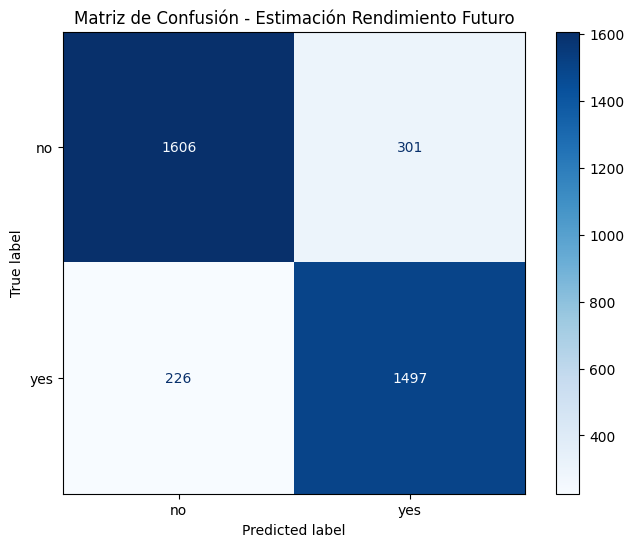

In [ ]:
# Seleccionamos el modelo de Gradient Boosting con mejor resultado
mejor_modelo_gb = grid_boosting.best_estimator_

# Evaluación outer con el conjunto de test
y_pred_test = mejor_modelo_gb.predict(X_test)

print("--- EVALUACIÓN OUTER ---")
print(f"Accuracy en Test: {mejor_modelo_gb.score(X_test, y_test):.4f}\n")
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred_test))

# Matriz de Confusión
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, cmap='Blues', ax=ax)
ax.set_title('Matriz de Confusión - Estimación Rendimiento Futuro')
plt.show()

Como podemos observar, el rendimiento en el conjunto de test (0.8548) es parecido al obtenido en el entrenamiento, lo que nos permite concluir que el modelo no presenta overfitting y tiene una excelente capacidad de generalización ante datos no vistos.

Por otra parte, el hecho de que la precisión global, el recall y el f1-score se sitúen en el 85%, indica que el modelo es muy robusto y no presenta sesgos, es decir, es capaz de identificar con la misma eficacia tanto a los clientes que aceptarán el depósito como a los que no.

Por otro lado, vamos a desglosar los resultados de la matriz de confusión:

*   Verdaderos Positivos (1497): Clientes que contrataron el depósito y el modelo los identificó correctamente.

*   Verdaderos Negativos (1606): Clientes que no contrataron y el modelo acertó al descartarlos.

*   Falsos Positivos (301): Clientes a los que el modelo predijo que contratarían, pero no lo hicieron. Representan un coste de contacto innecesario.

*   Falsos Negativos (226): Clientes que sí habrían contratado, pero el modelo no los detectó. Es una oportunidad de negocio perdida.

### <u>Modelo final</u>

Entrenamos el modelo final sobre todos los datos disponibles (train + test) con los mejores hiperparámetros encontrados por GridSearch.

In [ ]:
# Combinamos todos los datos disponibles
X_full = pd.concat([X_train, X_test])
y_full = np.concatenate([y_train, y_test])

# Entrenamos el modelo final con los mejores parámetros
modelo_final = grid_boosting.best_estimator_
modelo_final.fit(X_full, y_full)

# Guardamos el modelo
joblib.dump(modelo_final, 'modelo_final.joblib')

['modelo_final.joblib']

## <u>**Predicciones específicas de instancias**</u>

In [ ]:
# Recreamos la instancia a probar
data_prueba = {
    'age': [35],
    'job': ['admin.'],
    'marital': ['married'],
    'education': ['primary'],
    'default': ['no'],
    'balance': [1000],
    'housing': ['no'],
    'loan': ['no'],
    'contact': ['cellular'],
    'day': [15],
    'month': ['jan'],
    'duration': [75],
    'campaign': [1],
    'pdays': [-1],
    'previous': [0],
    'poutcome': ['success']
}

df_test = pd.DataFrame(data_prueba)

# Adaptación de la variable nueva
df_test['contacted_before'] = (df_test['pdays'] != -1).astype(int)

# Ordenamos las features
df_test = df_test[modelo_final.feature_names_in_]

# Predecimos
pred = modelo_final.predict(df_test)
prob = modelo_final.predict_proba(df_test) if hasattr(modelo_final, "predict_proba") else "N/A"

print(f"=== RESULTADO EN COLAB ===")
print(f"Predicción: {pred[0]}")
print(f"Probabilidades [No, Sí]: {prob}")

=== RESULTADO EN COLAB ===
Predicción: no
Probabilidades [No, Sí]: [[0.57101937 0.42898063]]


## <u>**Uso de IA generativa**</u>

Finalmente, nos gustaría mencionar brevemente para qué hemos usado la IA generativa. En nuestro caso, la hemos usado para corregir problemas de la práctica y asegurarnos de que no se nos ha escapado nada:

*   Preproceso de pdays: Al principio se nos olvidó preprocesar pdays, y fue gracias a la IA, que nos avisó del problema, y así pudimos solucionarlo.
*   Data leakage: Al realizar los hiperparámetros por omisión y los ajustes de hiperparámetros en los puntos 3 y 4, se nos había pasado que en el enunciado de la práctica ponía que test solamente se podía usar al final una vez decidido cuál es el mejor modelo, por lo que al principio para comparar las alternativas usamos el test, pero gracias al aviso pudimos cambiarlo para utilizar así 3-fold CV.
* Ayuda para centralizar partes del proyecto y aprender a usar las bibliotecas nuevas
* Ayudó a hacer la base del streamlit

